# Step 1:
    - Load data
        - cleaning process
# Step 2:
    - Problem identification (Regression / Classification)
# Step 3:
    - Data separate input / X and y
# Step 4:
    - Split the data into Training data and Testing data
# Step 5:
    - Select Model / Algorithm
# Step 6:
    - Train the Model / Fit the Model
# Step 7:
    - Evaluate the models performance on training data
# Step 8:
    - Evaluate on Testing data
# Step 9:
    - Evaluate the models performance on training data
# Step 10:
    - Deployed model prediction

In [1]:
import pandas as pd
data = pd.read_csv("weight-height.csv")

In [2]:
data.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Gender  10000 non-null  str    
 1   Height  10000 non-null  float64
 2   Weight  10000 non-null  float64
dtypes: float64(2), str(1)
memory usage: 283.3 KB


In [4]:
data.Gender = data.Gender.apply(lambda x:1 if x=='Male' else 0)

In [5]:
data

,Gender,Height,Weight
0,1,73.847017,241.893563
1,1,68.781904,162.310473
2,1,74.110105,212.740856
3,1,71.730978,220.042470
4,1,69.881796,206.349801
...,...,...,...
9995,0,66.172652,136.777454
9996,0,67.067155,170.867906
9997,0,63.867992,128.475319
9998,0,69.034243,163.852461


In [6]:
data.corr()

,Gender,Height,Weight
Gender,1.000000,0.691072,0.796723
Height,0.691072,1.000000,0.924756
Weight,0.796723,0.924756,1.000000


<Axes: title={'center': 'Weight and Height in adults'}, xlabel='Height', ylabel='Weight'>

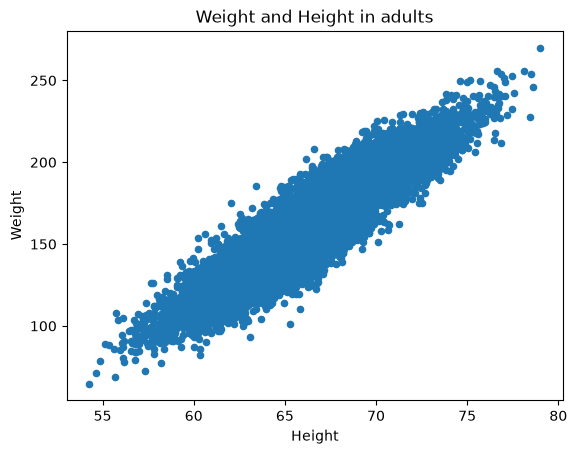

In [9]:
data.plot(kind='scatter', x='Height', y='Weight', title="Weight and Height in adults")

# Since the target column is Continous value : Regression

In [19]:
X = data.drop(['Weight','Gender'], axis=1)
y = data.Weight

In [20]:
X

,Height
0,73.847017
1,68.781904
2,74.110105
3,71.730978
4,69.881796
...,...
9995,66.172652
9996,67.067155
9997,63.867992
9998,69.034243


In [21]:
y

0       241.893563
1       162.310473
2       212.740856
3       220.042470
4       206.349801
           ...    
9995    136.777454
9996    170.867906
9997    128.475319
9998    163.852461
9999    113.649103
Name: Weight, Length: 10000, dtype: float64

In [31]:
# x_train,y_train = X.iloc[:7000],y.iloc[7000:]

### there is shuffle problem to do it manually so we will use machine learning library

In [32]:
from sklearn.model_selection import train_test_split
X_train,X_test, y_train,y_test = train_test_split(X,y, test_size=.30, random_state=0)

In [37]:
X_train.shape, X_test.shape

((7000, 1), (3000, 1))

In [39]:
from sklearn.linear_model import LinearRegression
slr = LinearRegression()

In [40]:
slr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[7.72]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Height']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-351.2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [41]:
slr.coef_

array([7.72410571])

In [42]:
slr.intercept_

np.float64(-351.1768431755373)

# y = 7.72 x - 351.17

# Prediction on training Data

In [44]:
y_pred = slr.predict(X_train)

In [45]:
len(y_pred)

7000

# Performance Evaluation
    - r2 Score

In [46]:
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

In [47]:
root_mean_squared_error(y_train, y_pred)

12.16712336726137

In [48]:
mean_absolute_error(y_train, y_pred)

9.704446843631068

In [49]:
r2_score(y_train, y_pred)

0.8558937147068257

In [50]:
y_pred_test = slr.predict(X_test)

In [52]:
r2_score(y_test, y_pred_test)

0.8535056083267061

In [56]:
def predict_weight(height):
    return slr.predict(height)*0.45

In [59]:
height_inch = (float(input("Enter your height: ")))*12
predict_weight([[height_inch]])

Enter your height:  5.8


D:\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([83.8894114])

# Save model

In [60]:
import pickle, joblib   # use pickle or joblib

In [61]:
joblib.dump(slr, 'slr.pkl')

['slr.pkl']

In [62]:
model = joblib.load('slr.pkl')

In [64]:
def predict_weight(height):
    return model.predict(height)*0.45

In [67]:
height_inch = (float(input("Enter your height: ")))*12
predict_weight([[height_inch]])

Enter your height:  5.8


D:\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([83.8894114])